In [26]:
#Ejercicio 1
import numpy as np

#Definimos la función que aplica los tres métodos 
def calcular_derivadas(f, x0, h):
    # Fórmulas extraídas directamente de los apuntes del laboratorio
    df_adelante = (f(x0 + h) - f(x0)) / h
    df_atras = (f(x0) - f(x0 - h)) / h
    df_central = (f(x0 + h) - f(x0 - h)) / (2 * h)
    return df_adelante, df_atras, df_central

#Definimos las funciones
def f1(x):
    return np.sqrt(x)

def f2(x):
    return np.sin(x)

def f3(x):
    return np.log(x)

def f4(x):
    return (x**2) * np.sin(x)

def f5(x):
    return np.exp(x) / ((x**2) + 1)

#Calculamos las derivadas exactas analíticas para poder compararlas 
exacta_1 = 1 / (2 * np.sqrt(4)) 
exacta_2 = np.cos(np.pi)
exacta_3 = 1 / 1
exacta_4 = (2 * 2 * np.sin(2)) + ((2**2) * np.cos(2))
exacta_5 = (np.exp(1) * (1**2 + 1) - np.exp(1) * 2 * 1) / ((1**2 + 1)**2)

#Agrupamos los datos en listas para poder recorrerlos con un bucle
ejercicios = [[f1, 4, exacta_1, "f(x) = sqrt(x)"], [f2, np.pi, exacta_2, "f(x) = sin(x)"], [f3, 1, exacta_3, "f(x) = log(x)"],
[f4, 2, exacta_4, "f(x) = x^2 * sin(x)"], [f5, 1, exacta_5, "f(x) = e^x / (x^2 + 1)"]]

#Creamos una lista con los valores de h
valores_h = [0.1, 0.01, 0.001, 0.0001, 0.00001, 0.000001]

#Recorremos la lista y calculamos las estimaciones
for datos in ejercicios:
    funcion = datos[0]
    x0 = datos[1]
    exacta = datos[2]
    nombre = datos[3]
    
    print("Función:", nombre, "evaluada en x0 =", x0)
    print("Derivada analítica:", exacta)
    print("h | Adelante | Atrás | Central")
    
    #Probamos todos los valores de h para esta función
    for h in valores_h:
        adelante, atras, central = calcular_derivadas(funcion, x0, h)
        print(h, "|", adelante, "|", atras, "|", central)
    
    print("\n") 

Función: f(x) = sqrt(x) evaluada en x0 = 4
Derivada analítica: 0.25
h | Adelante | Atrás | Central
0.1 | 0.2484567313165842 | 0.2515823418685015 | 0.25001953659254283
0.01 | 0.249843945007866 | 0.2501564456182104 | 0.2500001953130382
0.001 | 0.24998437695300524 | 0.25001562695337043 | 0.25000000195318783
0.0001 | 0.2499984375203823 | 0.2500015625206409 | 0.2500000000205116
1e-05 | 0.24999984375995152 | 0.25000015624332406 | 0.2500000000016378
1e-06 | 0.24999998426977754 | 0.25000001557806684 | 0.2499999999239222


Función: f(x) = sin(x) evaluada en x0 = 3.141592653589793
Derivada analítica: -1.0
h | Adelante | Atrás | Central
0.1 | -0.9983341664682823 | -0.9983341664682823 | -0.9983341664682823
0.01 | -0.9999833334166452 | -0.9999833334166451 | -0.9999833334166451
0.001 | -0.9999998333332315 | -0.9999998333332315 | -0.9999998333332315
0.0001 | -0.9999999983354435 | -0.9999999983354436 | -0.9999999983354435
1e-05 | -0.9999999999898844 | -0.9999999999898845 | -0.9999999999898845
1e-06 | 

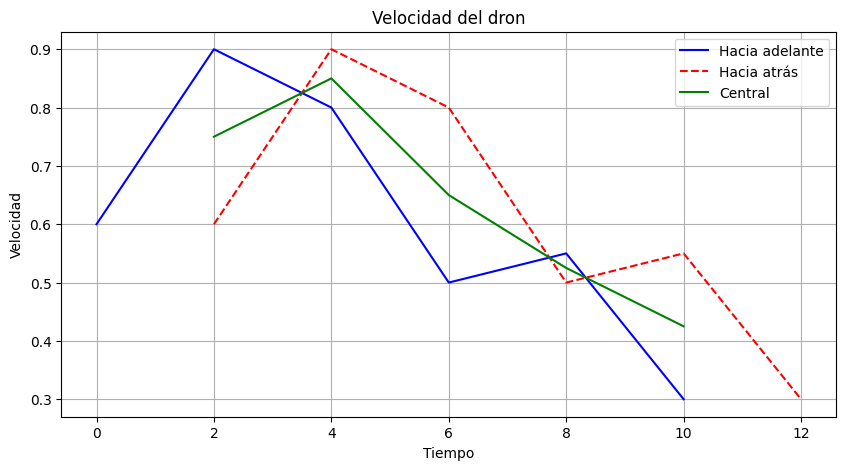

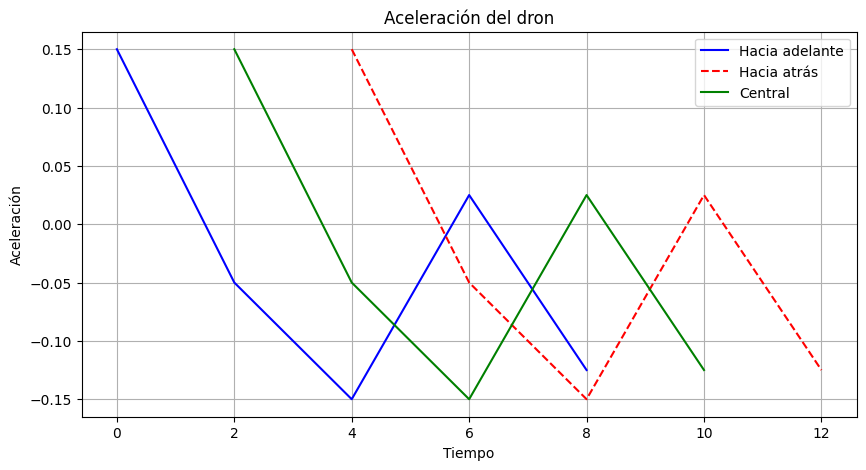

In [14]:
#Ejercicio2
import numpy as np
import matplotlib.pyplot as plt

#Definimos los datos de la tabla
t = np.array([0, 2, 4, 6, 8, 10, 12])
r = np.array([0.7, 1.9, 3.7, 5.3, 6.3, 7.4, 8.0])

#Observamos que el tiempo es constante porque va de 2 en 2
h = 2

#Calculamos la velocidad, es decir, la primera derivada
#Aplicamos el método hacia delante
v_adelante = [(r[i+1] - r[i]) / h for i in range(len(r)-1)]
t_adelante = t[:-1] 

#Aplicamos el método hacia atrás
v_atras = [(r[i] - r[i-1]) / h for i in range(1, len(r))]
t_atras = t[1:]

#Aplicamos método central
v_central = (r[2:] - r[:-2]) / (2 * h)
t_central = t[1:-1] 


#Calculamos la aceleracion, es decir, la segunda derivada
#Aplicamos metodo central
a_central = (r[2:] - 2*r[1:-1] + r[:-2]) / (h**2)
t_a_central = t[1:-1]

#Aplicamos metodo hacia delante
a_adelante = [(v_adelante[i+1] - v_adelante[i]) / h for i in range(len(v_adelante)-1)]
t_a_adelante = t_adelante[:-1]

#Aplicamos método hacia atrás
a_atras = [(v_atras[i] - v_atras[i-1]) / h for i in range(1, len(v_atras))]
t_a_atras = t_atras[1:]

#Obtenemos las graficas

#Grafica de velocidades
plt.figure(figsize=(10, 5))
plt.plot(t_adelante, v_adelante, color='blue', label='Hacia adelante')
plt.plot(t_atras, v_atras, color='red', label='Hacia atrás', linestyle='--')
plt.plot(t_central, v_central, color='green', label='Central')

plt.xlabel('Tiempo')
plt.ylabel('Velocidad')
plt.title('Velocidad del dron')
plt.legend()
plt.grid(True)
plt.show()

#Grafica de aceleraciones
plt.figure(figsize=(10, 5))
plt.plot(t_a_adelante, a_adelante, color='blue', label='Hacia adelante')
plt.plot(t_a_atras, a_atras, color='red', label='Hacia atrás', linestyle='--')
plt.plot(t_a_central, a_central, color='green', label='Central')

plt.xlabel('Tiempo')
plt.ylabel('Aceleración')
plt.title('Aceleración del dron')
plt.legend()
plt.grid(True)
plt.show()

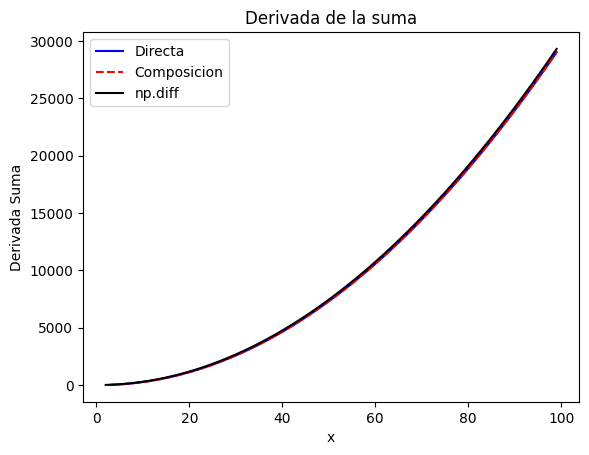

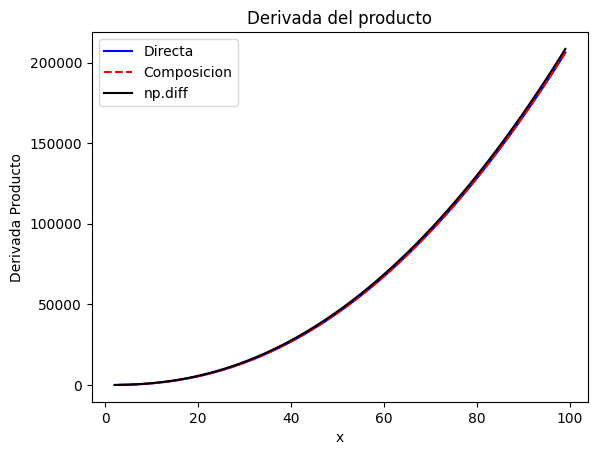

In [13]:
# Ejercicio 3
import numpy as np
import matplotlib.pyplot as plt

# A)

#Establecemos el dominio y calculamos el tamaño de h
x = np.linspace(2, 100, 100)
h = x[1] - x[0]

#Definimos las funciones y calculamos
f = x**3 - 2*(x**2)
g = np.log2(x)
suma_fg = f + g
prod_fg = f * g

# B)

#Aplicamos método central, para ello primero operamos todo y despues derivamos
df_suma_directa = (suma_fg[2:] - suma_fg[:-2]) / (2 * h)
df_prod_directa = (prod_fg[2:] - prod_fg[:-2]) / (2 * h)

#Seguimos la regla de descomposicion
df_f = (f[2:] - f[:-2]) / (2 * h)
df_g = (g[2:] - g[:-2]) / (2 * h)

# Aplicamos regla de la suma y la del producto
df_suma_comp = df_f + df_g
f_recortada = f[1:-1]
g_recortada = g[1:-1]

df_prod_comp = (f_recortada * df_g) + (df_f * g_recortada)

#C)

#Usamos np.diff()
df_suma_predet = np.diff(suma_fg) / np.diff(x)
df_prod_predet = np.diff(prod_fg) / np.diff(x)

# D) 

#Mostramos las graficas, para ello recortamos el eje x para que no nos de un error de tamaño
x_central = x[1:-1]
x_predet = x[:-1] 

#Grafica suma
plt.plot(x_central, df_suma_directa, label='Directa', color='blue')
plt.plot(x_central, df_suma_comp, label='Composicion', color='red', linestyle='--')
plt.plot(x_predet, df_suma_predet, label='np.diff', color='black')
plt.xlabel('x')
plt.ylabel('Derivada Suma')
plt.title('Derivada de la suma')
plt.legend()
plt.show()

#Grafica producto
plt.plot(x_central, df_prod_directa, label='Directa', color='blue')
plt.plot(x_central, df_prod_comp, label='Composicion', color='red', linestyle='--')
plt.plot(x_predet, df_prod_predet, label='np.diff', color='black')
plt.xlabel('x')
plt.ylabel('Derivada Producto')
plt.title('Derivada del producto')
plt.legend()
plt.show()

In [ ]:
#Ejercicio4
import numpy as np
import sympy as sp
import numdifftools as nd

#Definimos los puntos
punto_A = np.array([1.0, 1.0, 1.0])
punto_B = np.array([0.0, 0.0, 3.0])
punto_C = np.array([3.0, 2.0, 1.0])

#Definimos los vectores direccion
v_a = np.array([1.0, 0.0, -1.0])
v_b = np.array([8.0, 4.0, -1.0])
v_c = np.array([1.0, -1.0, np.sqrt(2)])

#Normalizamos el vector
u_a = v_a / np.linalg.norm(v_a)
u_b = v_b / np.linalg.norm(v_b)
u_c = v_c / np.linalg.norm(v_c)

#Definimos las funciones
def f1_num(v):
    x, y, z = v
    return np.sqrt(x * y) - np.log(z)

def f2_num(v):
    x, y, z = v
    return np.exp(x * y) + y * (z**2)

def f3_num(v):
    x, y, z = v
    return (x + y) / (x - y)

#Definimos la funciones para sympy
xs, ys, zs = sp.symbols('x y z')

f1_sym = sp.sqrt(xs * ys) - sp.log(zs)
f2_sym = sp.exp(xs * ys) + ys * (zs**2)
f3_sym = (xs + ys) / (xs - ys)

#Funcion que aplica el algoritmo de diferencias centrales
def mi_gradiente_central(f, punto, h=1e-5):
    gradiente = np.zeros(len(punto))
    for i in range(len(punto)):
        #Creamos variaciones pequeñas solo en la componente i
        p_mas = punto.copy()
        p_menos = punto.copy()
        p_mas[i] += h
        p_menos[i] -= h
        #Aplicamos la fórmula central: (f(x+h) - f(x-h)) / 2h
        gradiente[i] = (f(p_mas) - f(p_menos)) / (2 * h)
    return gradiente

#Definimos una lista con los datos y realizamos los calculos
datos_ejercicio = [("Función 1", f1_num, f1_sym, punto_A, u_a), ("Función 2", f2_num, f2_sym, punto_B, u_b), ("Función 3", f3_num, f3_sym, punto_C, u_c)]

for nombre, f_num, f_sym, punto, unitario in datos_ejercicio:
    print(f"-{nombre} ")
    
    #Calculo con NumDiffTools
    grad_nd = nd.Gradient(f_num)(punto)
    der_dir_nd = np.dot(grad_nd, unitario)
    
    #Calculo con SymPy: derivadas parciales, sustituimos valores y convertimos en float
    grad_parciales = [sp.diff(f_sym, var) for var in (xs, ys, zs)]
    grad_sp = np.array([float(d.subs({xs:punto[0], ys:punto[1], zs:punto[2]})) for d in grad_parciales])
    der_dir_sp = np.dot(grad_sp, unitario)
    
    #Calculo con Algoritmo diferencia centrales
    grad_mi = mi_gradiente_central(f_num, punto)
    der_dir_mi = np.dot(grad_mi, unitario)
    
    print(f"GRADIENTE:")
    print(f"  NumDiffTools: {grad_nd}")
    print(f"  SymPy:        {grad_sp}")
    print(f"  Propio:       {grad_mi}")
    print(f"DERIVADA DIRECCIONAL:")
    print(f"  Resultado:    {der_dir_nd:.6f}\n")

-Función 1 
GRADIENTE:
  NumDiffTools: [ 0.5  0.5 -1. ]
  SymPy:        [ 0.5  0.5 -1. ]
  Propio:       [ 0.5  0.5 -1. ]
DERIVADA DIRECCIONAL:
  Resultado:    1.060660

-Función 2 
GRADIENTE:
  NumDiffTools: [0. 9. 0.]
  SymPy:        [0. 9. 0.]
  Propio:       [0. 9. 0.]
DERIVADA DIRECCIONAL:
  Resultado:    4.000000

-Función 3 
GRADIENTE:
  NumDiffTools: [-4.  6.  0.]
  SymPy:        [-4.  6.  0.]
  Propio:       [-4.  6.  0.]
DERIVADA DIRECCIONAL:
  Resultado:    -5.000000




- Curva 1 
Resultados para r = 0:
  Vector Tangente: [0.707106781186548 0 0.707106781186548]
  Vector Normal:   [0 1.00000000000000 0]
  Vector Binormal: [-0.707106781186548 0 0.707106781186548]
Resultados para r = pi/4:
  Vector Tangente: [0.0938056504371257 0.780424057213105 0.618173754594211]
  Vector Normal:   [-0.962736559661162 0.229298282658238 -0.143389728578350]
  Vector Binormal: [-0.253650974052650 -0.581687707015559 0.772852246467022]
Resultados para r = pi:
  Vector Tangente: [-0.290256448899436 -0.911867527519529 0.290256448899436]
  Vector Normal:   [0.943347359012233 -0.323609037618863 -0.0733004162064517]
  Vector Binormal: [0.160769879383345 0.252536735994616 0.954137433945577]
Resultados para r = 10:
  Vector Tangente: [0.455580704984877 -0.884670729524186 0.0990147542976674]
  Vector Normal:   [0.889437646959690 0.456954453501234 -0.00965917161040985]
  Vector Binormal: [-0.0367000465434690 0.0924679822886496 0.995039084074175]

- Curva 2 
Resultados para r = 0:
  

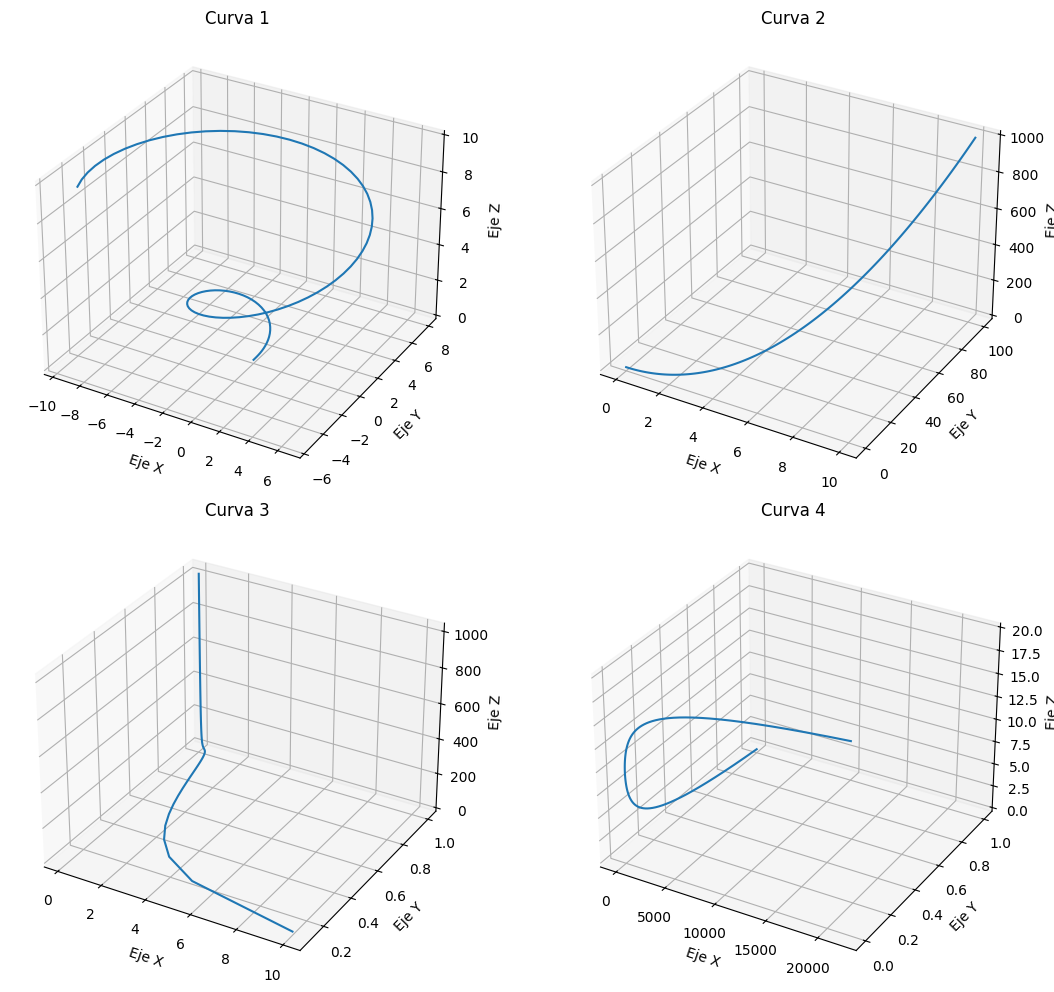

In [24]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

#Definimos r como nuestra variable para las cuentas
r = sp.symbols('r', real=True)

#Almacenamos nuestras curvas
curvas = [sp.Matrix([r*sp.cos(r), r*sp.sin(r), r]), sp.Matrix([r, r**2, r**3]),sp.Matrix([1/r, sp.tanh(r), 2**r]), sp.Matrix([sp.exp(r), sp.exp(-r), 2*r])]
nombres = ["Curva 1", "Curva 2", "Curva 3", "Curva 4"]

#Puntos de evaluacion
puntos_evaluacion = [0, sp.pi/4, sp.pi, 10]

#Definimos una funcion para calcular el vector tangente, normal y binormal
def sacar_vectores_curva(curva, valor_r):
    #Sacamos la primera y segunda derivada
    derivada1 = curva.diff(r)
    derivada2 = curva.diff(r, 2)
    
    #Sustituimos r por el valor correspondiente
    v1 = derivada1.subs(r, valor_r)
    v2 = derivada2.subs(r, valor_r)

    #Calculamos vector tangente
    T = v1 / v1.norm()
    
    #Calculamos vector binomial
    producto_v = v1.cross(v2)
    B = producto_v / producto_v.norm()
    
    #Calculamos el vector normal
    N = B.cross(T)
    
    return T.evalf(), N.evalf(), B.evalf()

#Mostramos la informacion para todas las curvas
for i, curva in enumerate(curvas):
    print(f"\n- {nombres[i]} ")
    for p in puntos_evaluacion:
        tangente, normal, binormal = sacar_vectores_curva(curva, p)
        print(f"Resultados para r = {p}:")
        print(f"  Vector Tangente: {np.array(tangente).flatten()}")
        print(f"  Vector Normal:   {np.array(normal).flatten()}")
        print(f"  Vector Binormal: {np.array(binormal).flatten()}")


#Dibujamos las graficas
fig = plt.figure(figsize=(12, 10))

for i, curva in enumerate(curvas):
    #Combertimos la funcion sympy en algo que python entiendo (gracias a .lambdify)
    dibujoX = sp.lambdify(r, curva[0], 'numpy')
    dibujoY = sp.lambdify(r, curva[1], 'numpy')
    dibujoZ = sp.lambdify(r, curva[2], 'numpy')
    
    #Ponemos valores a r
    r_datos = np.linspace(0.1, 10, 100) if i == 2 else np.linspace(0, 10, 100)
    
    #Sacamos las listas de puntos xyz
    x_p = dibujoX(r_datos)
    y_p = dibujoY(r_datos)
    z_p = dibujoZ(r_datos)
    
    ax = fig.add_subplot(2, 2, i+1, projection='3d')
    ax.plot(x_p, y_p, z_p)
    ax.set_title(nombres[i])
    ax.set_xlabel('Eje X')
    ax.set_ylabel('Eje Y')
    ax.set_zlabel('Eje Z')

plt.tight_layout()
plt.show()